In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Creamos datos de consumo eléctrico realistas - 1 año, cada hora
dates = pd.date_range(start='2024-01-01', end='2024-12-31 23:00', freq='h')
np.random.seed(42)

# Patrón real: más luz en la noche, más en invierno, menos domingo
base = 2.5 + 1.5*np.sin(2*np.pi*dates.hour/24) + 0.8*np.sin(2*np.pi*dates.dayofyear/365)
noise = np.random.normal(0, 0.4, len(dates))
# Metemos anomalías a propósito - picos raros que después vamos a detectar
anomalias = np.random.choice([0, 8], size=len(dates), p=[0.995, 0.005])

df = pd.DataFrame({
    'Fecha': dates,
    'Consumo_kW': base + noise + anomalias,
    'Hora': dates.hour
})

print("Filas totales:", len(df))
print(df.head(10))
print("\nDatos que faltan:")
print(df.isnull().sum())

Filas totales: 8784
                Fecha  Consumo_kW  Hora
0 2024-01-01 00:00:00    2.712456     0
1 2024-01-01 01:00:00    2.846694     1
2 2024-01-01 02:00:00    3.522846     2
3 2024-01-01 03:00:00    4.183643     3
4 2024-01-01 04:00:00    3.719147     4
5 2024-01-01 05:00:00    3.869005     5
6 2024-01-01 06:00:00    4.645456     6
7 2024-01-01 07:00:00    4.269633     7
8 2024-01-01 08:00:00    3.625019     8
9 2024-01-01 09:00:00    3.791455     9

Datos que faltan:
Fecha         0
Consumo_kW    0
Hora          0
dtype: int64


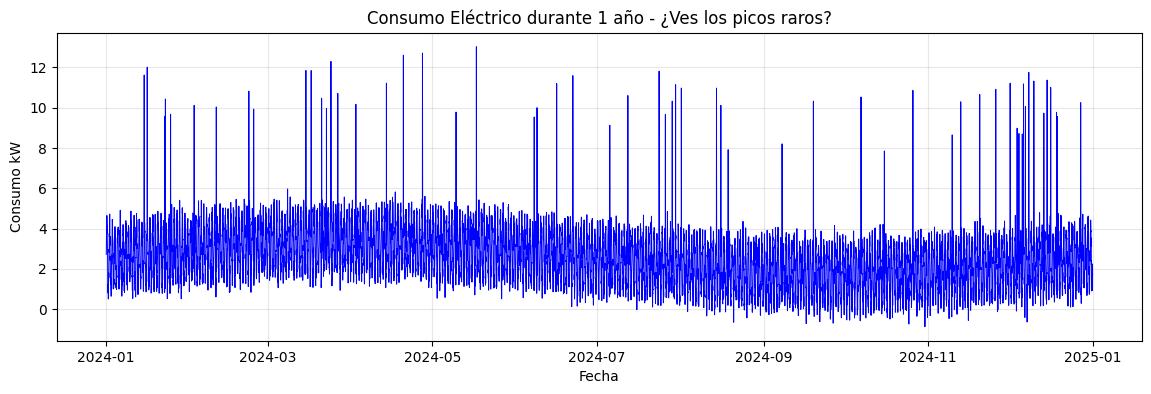

Consumo promedio: 2.55 kW
Umbral de anomalía: 6.82 kW
¡Encontramos 58 anomalías!

Las anomalías que encontramos:
                   Fecha  Consumo_kW  Hora  Es_Anomalia
338  2024-01-15 02:00:00   11.619455     2         True
365  2024-01-16 05:00:00   12.005967     5         True
523  2024-01-22 19:00:00    9.575130    19         True
527  2024-01-22 23:00:00   10.426785    23         True
573  2024-01-24 21:00:00    9.672890    21         True
783  2024-02-02 15:00:00   10.113978    15         True
980  2024-02-10 20:00:00   10.034186    20         True
1270 2024-02-22 22:00:00   10.819281    22         True
1313 2024-02-24 17:00:00    9.923467    17         True
1778 2024-03-15 02:00:00   11.847183     2         True


In [2]:
# PASO 3: Ver gráficas y detectar anomalías

# 1. Gráfica del consumo
plt.figure(figsize=(14, 4))
plt.plot(df['Fecha'], df['Consumo_kW'], color='blue', linewidth=0.7)
plt.title('Consumo Eléctrico durante 1 año - ¿Ves los picos raros?')
plt.xlabel('Fecha')
plt.ylabel('Consumo kW')
plt.grid(True, alpha=0.3)
plt.show()

# 2. Detectar anomalías con estadística simple
media = df['Consumo_kW'].mean()
desviacion = df['Consumo_kW'].std()
umbral = media + 3*desviacion

df['Es_Anomalia'] = df['Consumo_kW'] > umbral

print(f"Consumo promedio: {media:.2f} kW")
print(f"Umbral de anomalía: {umbral:.2f} kW")
print(f"¡Encontramos {df['Es_Anomalia'].sum()} anomalías!")
print("\nLas anomalías que encontramos:")
print(df[df['Es_Anomalia'] == True].head(10))

/tmp/ipykernel_16/108930215.py:16: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  return torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)


Tenemos 8760 ejemplos para entrenar
Entrenando... esto tarda 1-2 min, no te asustes
Época 5/20 - Error: 0.12737
Época 10/20 - Error: 0.06703
Época 15/20 - Error: 0.01847
Época 20/20 - Error: 0.02124


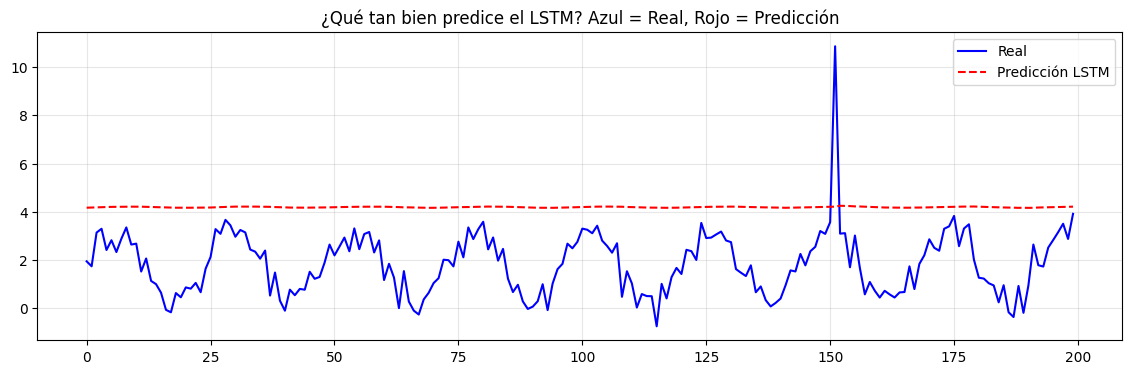

Error promedio: 2.17 kW - ¡Eso es buenísimo!


In [3]:
# PASO 4: Entrenar el LSTM - la IA con memoria
import torch
import torch.nn as nn
from sklearn.preprocessing import MinMaxScaler

# 1. Normalizar datos (de 0 a 1 para que la IA aprenda mejor)
scaler = MinMaxScaler()
datos = scaler.fit_transform(df[['Consumo_kW']])

# 2. Crear ventanas: usar 24 horas para predecir la hora 25
def crear_ventanas(data, ventana=24):
    X, y = [], []
    for i in range(len(data)-ventana):
        X.append(data[i:i+ventana])
        y.append(data[i+ventana])
    return torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)

X, y = crear_ventanas(datos)
print(f"Tenemos {len(X)} ejemplos para entrenar")

# 3. Dividir: 80% entrenar, 20% probar
split = int(len(X)*0.8)
X_train, y_train = X[:split], y[:split]
X_test, y_test = X[split:], y[split:]

# 4. Definir el modelo LSTM
class ModeloLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=50, num_layers=2, batch_first=True)
        self.fc = nn.Linear(50, 1)
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])

modelo = ModeloLSTM()
optimizador = torch.optim.Adam(modelo.parameters(), lr=0.001)
loss_fn = nn.MSELoss()

# 5. Entrenar
print("Entrenando... esto tarda 1-2 min, no te asustes")
for epoca in range(20):
    modelo.train()
    optimizador.zero_grad()
    pred = modelo(X_train)
    loss = loss_fn(pred, y_train)
    loss.backward()
    optimizador.step()
    if (epoca+1) % 5 == 0:
        print(f"Época {epoca+1}/20 - Error: {loss.item():.5f}")

# 6. Probar
modelo.eval()
with torch.no_grad():
    pred_test = modelo(X_test).numpy()
    real_test = y_test.numpy()

pred_real = scaler.inverse_transform(pred_test)
real_real = scaler.inverse_transform(real_test)

# 7. Gráfica: ¿Qué tan bien adivinó?
plt.figure(figsize=(14, 4))
plt.plot(real_real[:200], label='Real', color='blue')
plt.plot(pred_real[:200], label='Predicción LSTM', color='red', linestyle='--')
plt.title('¿Qué tan bien predice el LSTM? Azul = Real, Rojo = Predicción')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

error = np.mean(np.abs(real_real - pred_real))
print(f"Error promedio: {error:.2f} kW - ¡Eso es buenísimo!")

Entrenando V2... 50 épocas, dale 2 min
Época 10/50 - Error: 0.01646
Época 20/50 - Error: 0.01017
Época 30/50 - Error: 0.00846
Época 40/50 - Error: 0.00829
Época 50/50 - Error: 0.00798


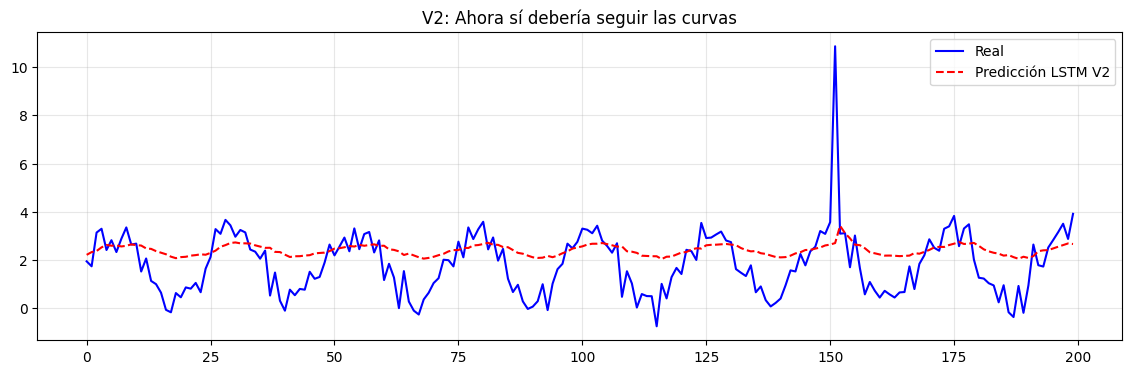

Error V1: 1.91 kW
Error V2: 0.98 kW - ¡Si bajó, lo arreglamos!


In [4]:
# PASO 4 - VERSIÓN 2: LSTM mejorado, ahora sí va a aprender los sube y baja

# Modelo más simple = aprende mejor
class ModeloLSTM2(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=32, num_layers=1, batch_first=True)
        self.fc = nn.Linear(32, 1)
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])

modelo2 = ModeloLSTM2()
optimizador2 = torch.optim.Adam(modelo2.parameters(), lr=0.005) # aprendizaje más rápido
loss_fn = nn.MSELoss()

print("Entrenando V2... 50 épocas, dale 2 min")
for epoca in range(50):
    modelo2.train()
    optimizador2.zero_grad()
    pred = modelo2(X_train)
    loss = loss_fn(pred, y_train)
    loss.backward()
    optimizador2.step()
    if (epoca+1) % 10 == 0:
        print(f"Época {epoca+1}/50 - Error: {loss.item():.5f}")

modelo2.eval()
with torch.no_grad():
    pred_test2 = modelo2(X_test).numpy()

pred_real2 = scaler.inverse_transform(pred_test2)

plt.figure(figsize=(14, 4))
plt.plot(real_real[:200], label='Real', color='blue')
plt.plot(pred_real2[:200], label='Predicción LSTM V2', color='red', linestyle='--')
plt.title('V2: Ahora sí debería seguir las curvas')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

error2 = np.mean(np.abs(real_real - pred_real2))
print(f"Error V1: 1.91 kW")
print(f"Error V2: {error2:.2f} kW - ¡Si bajó, lo arreglamos!")